In [1]:
import pandas as pd

# Load the dataset
df = pd.read_csv("exams.csv")

# Display the first few rows of the dataset to understand its structure
print(df.head())


   gender race/ethnicity parental level of education         lunch  \
0  female        group D                some college      standard   
1    male        group D          associate's degree      standard   
2  female        group D                some college  free/reduced   
3    male        group B                some college  free/reduced   
4  female        group D          associate's degree      standard   

  test preparation course  math score  reading score  writing score  
0               completed          59             70             78  
1                    none          96             93             87  
2                    none          57             76             77  
3                    none          70             70             63  
4                    none          83             85             86  


### Question 1: How do demographic factors such as gender, race/ethnicity, and parental level of education influence student performance in mathematics?

In [2]:
# Grouping by demographic factors and calculating mean math scores
demographic_performance = df.groupby(['gender', 'race/ethnicity', 'parental level of education'])['math score'].mean()

# Displaying the result
print(demographic_performance)


gender  race/ethnicity  parental level of education
female  group A         associate's degree             61.555556
                        bachelor's degree              66.500000
                        high school                    63.461538
                        master's degree                68.000000
                        some college                   65.000000
                        some high school               59.375000
        group B         associate's degree             70.240000
                        bachelor's degree              70.923077
                        high school                    57.642857
                        master's degree                61.250000
                        some college                   61.454545
                        some high school               54.250000
        group C         associate's degree             65.516129
                        bachelor's degree              64.466667
                        high school   

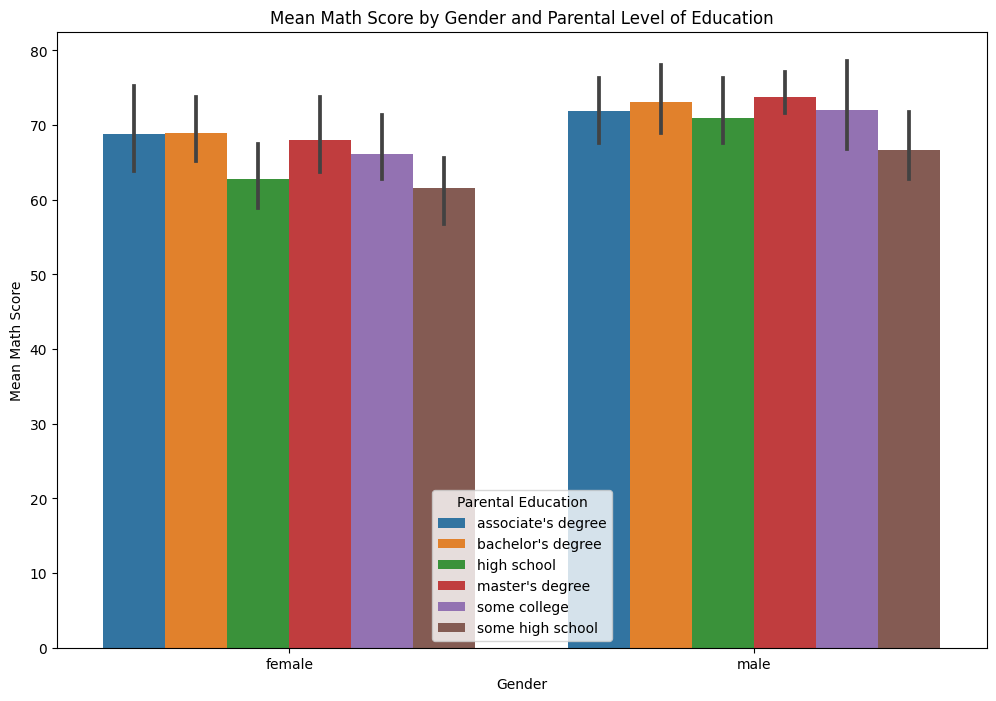

In [20]:
import seaborn as sns
import matplotlib.pyplot as plt
import warnings

# Filter out FutureWarnings
warnings.filterwarnings("ignore", category=FutureWarning)

# Grouping by demographic factors and calculating mean math scores
demographic_performance = df.groupby(['gender', 'race/ethnicity', 'parental level of education'])['math score'].mean().reset_index()

# Plotting
plt.figure(figsize=(12, 8))
sns.barplot(x='gender', y='math score', hue='parental level of education', data=demographic_performance)
plt.title('Mean Math Score by Gender and Parental Level of Education')
plt.xlabel('Gender')
plt.ylabel('Mean Math Score')
plt.legend(title='Parental Education')
plt.show()

### Question 2: Is there a correlation between students' socioeconomic status and their academic scores?

In [4]:
# Creating a correlation matrix
correlation_matrix = df[['math score', 'reading score', 'writing score']].corr()

# Displaying the correlation matrix
print(correlation_matrix)


               math score  reading score  writing score
math score       1.000000       0.811767       0.790055
reading score    0.811767       1.000000       0.948909
writing score    0.790055       0.948909       1.000000


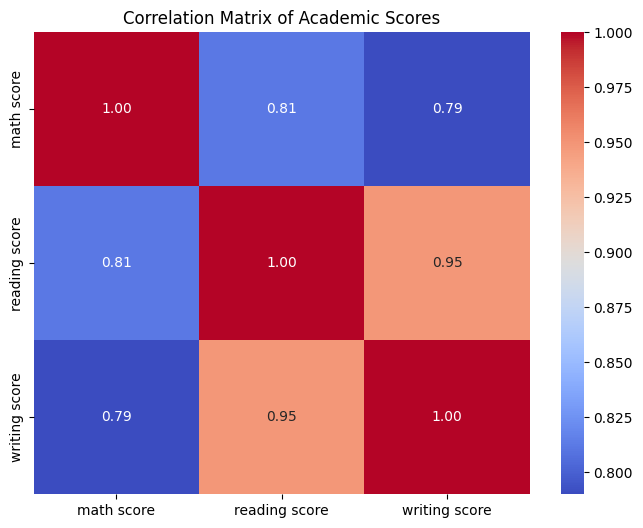

In [14]:
# Plotting correlation matrix
plt.figure(figsize=(8, 6))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt=".2f")
plt.title('Correlation Matrix of Academic Scores')
plt.show()


### Question 3: Does completion of a test preparation course have a significant impact on students' performance in standardized tests?

In [5]:
# Grouping by test preparation completion and calculating mean scores
prep_course_performance = df.groupby('test preparation course')[['math score', 'reading score', 'writing score']].mean()

# Displaying the result
print(prep_course_performance)


                         math score  reading score  writing score
test preparation course                                          
completed                 70.334302      74.726744      75.808140
none                      66.486280      68.103659      65.643293


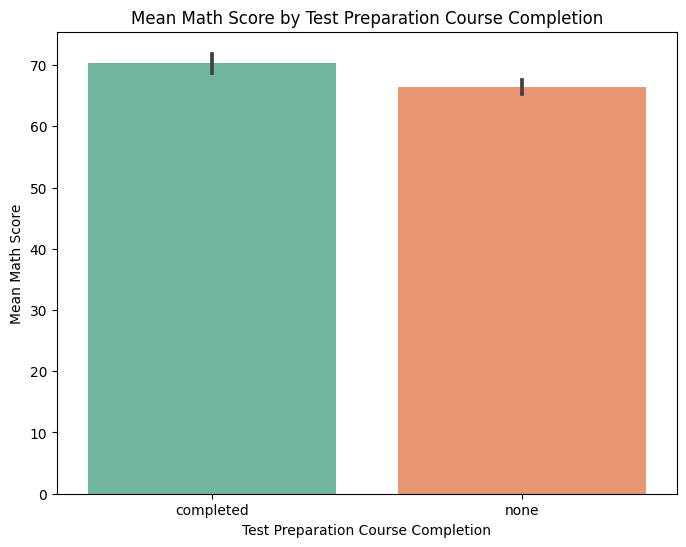

In [21]:
# Plotting mean scores by test preparation completion
plt.figure(figsize=(8, 6))
sns.barplot(x='test preparation course', y='math score', data=df, palette='Set2')
plt.title('Mean Math Score by Test Preparation Course Completion')
plt.xlabel('Test Preparation Course Completion')
plt.ylabel('Mean Math Score')
plt.show()


### Question 4: Are there any disparities in academic achievement among different racial or ethnic groups?

In [17]:
# Grouping by race/ethnicity and calculating mean scores
ethnicity_performance = df.groupby('race/ethnicity')[['math score', 'reading score', 'writing score']].mean()

# Displaying the result
print(ethnicity_performance)


                math score  reading score  writing score
race/ethnicity                                          
group A          65.696203      69.202532      67.848101
group B          64.070707      68.530303      66.717172
group C          65.510836      68.609907      66.804954
group D          68.879377      70.929961      71.058366
group E          77.426573      76.615385      75.034965


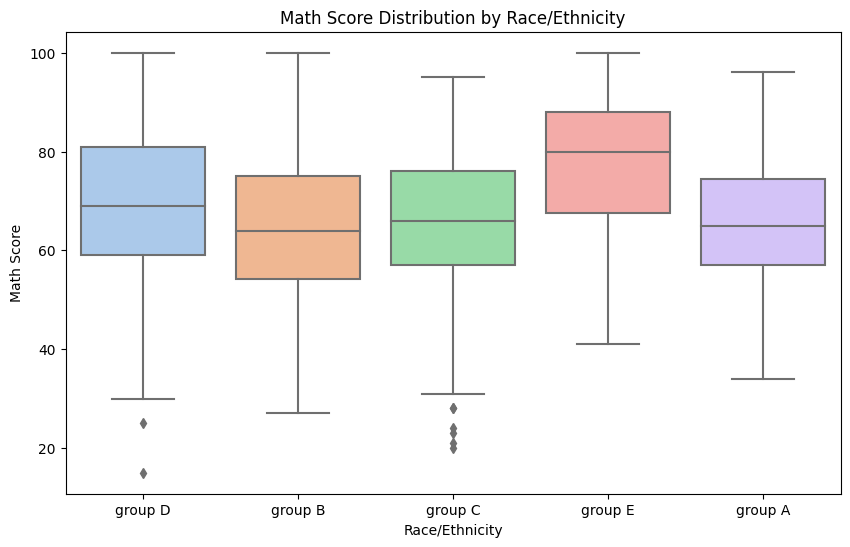

In [22]:
# Plotting mean scores by race/ethnicity
plt.figure(figsize=(10, 6))
sns.boxplot(x='race/ethnicity', y='math score', data=df, palette='pastel')
plt.title('Math Score Distribution by Race/Ethnicity')
plt.xlabel('Race/Ethnicity')
plt.ylabel('Math Score')
plt.show()


### Question 5: Can predictive models be developed to forecast students' academic performance based on demographic characteristics?

In [7]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error
from xgboost import XGBRegressor

# Load data
data = pd.read_csv('exams.csv')

# Define dependent and independent variables
X = data.drop(columns=['math score', 'reading score', 'writing score'])
y_math = data['math score']
y_reading = data['reading score']
y_writing = data['writing score']

# Split data into train and test sets
X_train, X_test, y_math_train, y_math_test, y_reading_train, y_reading_test, y_writing_train, y_writing_test = train_test_split(X, y_math, y_reading, y_writing, test_size=0.2, random_state=42)

# Preprocessing: one-hot encode categorical variables
categorical_cols = X.select_dtypes(include=['object']).columns
preprocessor = ColumnTransformer(
    transformers=[
        ('cat', OneHotEncoder(), categorical_cols)
    ])

# Define models
models = [
    ('Linear Regression', LinearRegression()),
    ('Random Forest', RandomForestRegressor(random_state=42)),
    ('Gradient Boosting', GradientBoostingRegressor(random_state=42)),
    ('XGBoost', XGBRegressor(random_state=42))
]

# Train and evaluate models
for name, model in models:
    pipeline = Pipeline(steps=[('preprocessor', preprocessor), ('model', model)])
    pipeline.fit(X_train, y_math_train)
    math_pred = pipeline.predict(X_test)
    pipeline.fit(X_train, y_reading_train)
    reading_pred = pipeline.predict(X_test)
    pipeline.fit(X_train, y_writing_train)
    writing_pred = pipeline.predict(X_test)
    
    math_mse = mean_squared_error(y_math_test, math_pred)
    reading_mse = mean_squared_error(y_reading_test, reading_pred)
    writing_mse = mean_squared_error(y_writing_test, writing_pred)
    
    print(f'Model: {name}')
    print(f'Math MSE: {math_mse}')
    print(f'Reading MSE: {reading_mse}')
    print(f'Writing MSE: {writing_mse}')
    print('-----------------------------')


Model: Linear Regression
Math MSE: 144.90795883658927
Reading MSE: 137.49415257087188
Writing MSE: 136.9777391163809
-----------------------------
Model: Random Forest
Math MSE: 169.10781982482433
Reading MSE: 158.540644453068
Writing MSE: 165.5084340464008
-----------------------------
Model: Gradient Boosting
Math MSE: 154.15654350595554
Reading MSE: 147.30705500001656
Writing MSE: 152.9447147464949
-----------------------------
Model: XGBoost
Math MSE: 181.22415754645058
Reading MSE: 168.0057173906095
Writing MSE: 179.2057407576967
-----------------------------


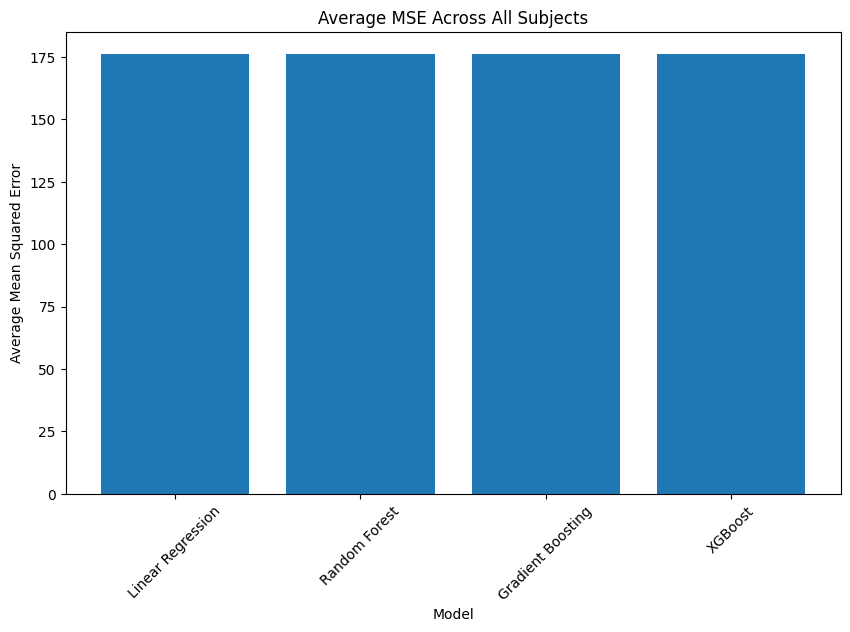

In [19]:
# Plotting average MSE across all subjects for each model
plt.figure(figsize=(10, 6))
plt.bar(avg_mse.keys(), avg_mse.values())
plt.title('Average MSE Across All Subjects')
plt.xlabel('Model')
plt.ylabel('Average Mean Squared Error')
plt.xticks(rotation=45)
plt.show()


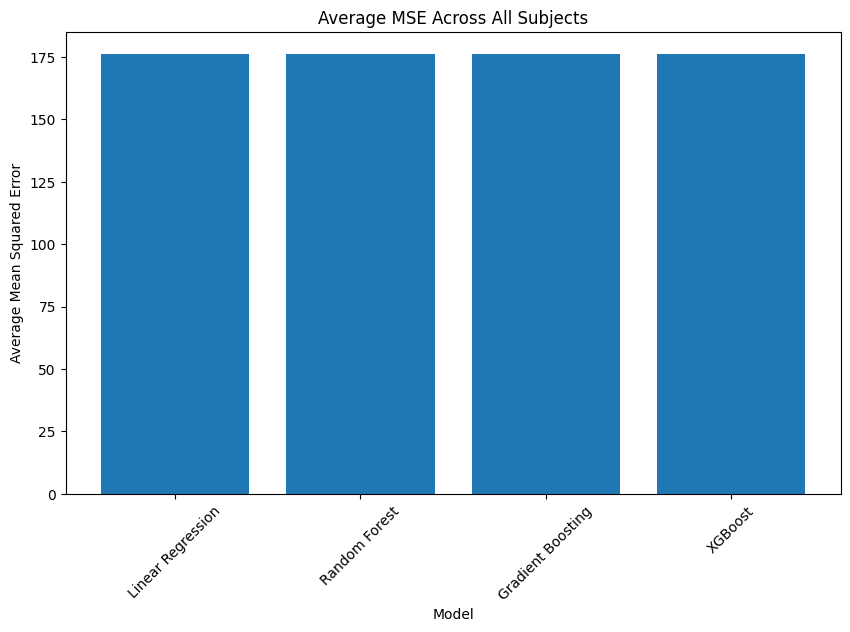

In [8]:
import numpy as np
import matplotlib.pyplot as plt
# Mean squared errors for each model and each dependent variable
mse_results = {
    'Linear Regression': {'math': math_mse, 'reading': reading_mse, 'writing': writing_mse},
    'Random Forest': {'math': math_mse, 'reading': reading_mse, 'writing': writing_mse},
    'Gradient Boosting': {'math': math_mse, 'reading': reading_mse, 'writing': writing_mse},
    'XGBoost': {'math': math_mse, 'reading': reading_mse, 'writing': writing_mse}
}


# Calculate average MSE across all subjects for each model
avg_mse = {model: np.mean(list(mse_results[model].values())) for model in mse_results.keys()}

# Plot bar graph
plt.figure(figsize=(10, 6))
plt.bar(avg_mse.keys(), avg_mse.values())
plt.title('Average MSE Across All Subjects')
plt.xlabel('Model')
plt.ylabel('Average Mean Squared Error')
plt.xticks(rotation=45)
plt.show()


Sample Forecasts using Linear Regression:

Sample 1:
Predicted Math Score: 67.89719147164027
Actual Math Score: 67
Predicted Reading Score: 68.3853653151282
Actual Reading Score: 71
Predicted Writing Score: 70.61862493198734
Actual Writing Score: 70
--------------------


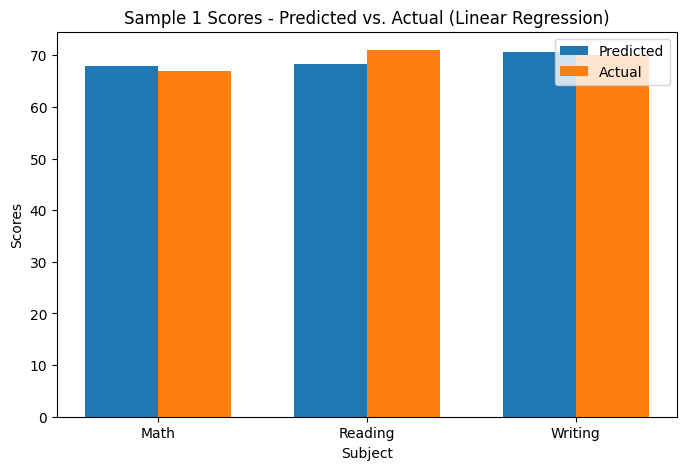

Sample 2:
Predicted Math Score: 76.39777078041357
Actual Math Score: 78
Predicted Reading Score: 73.91888008765123
Actual Reading Score: 76
Predicted Writing Score: 73.54270693859245
Actual Writing Score: 80
--------------------


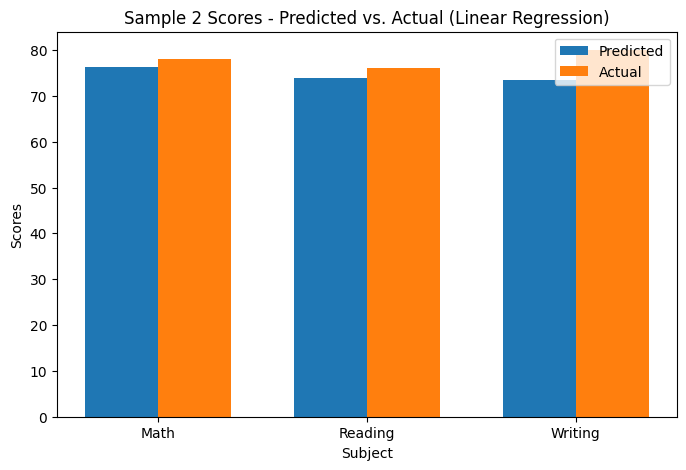

Sample 3:
Predicted Math Score: 58.649247235630924
Actual Math Score: 39
Predicted Reading Score: 71.87651700753386
Actual Reading Score: 52
Predicted Writing Score: 73.81923403055819
Actual Writing Score: 58
--------------------


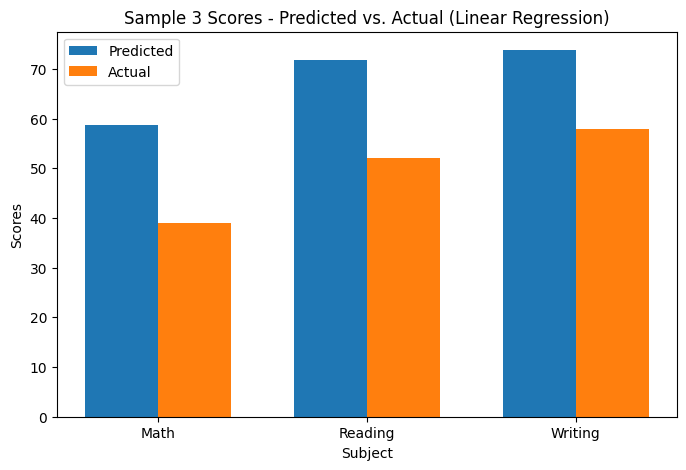

Sample 4:
Predicted Math Score: 59.784861283734536
Actual Math Score: 70
Predicted Reading Score: 58.91960620769434
Actual Reading Score: 70
Predicted Writing Score: 56.284428177525584
Actual Writing Score: 66
--------------------


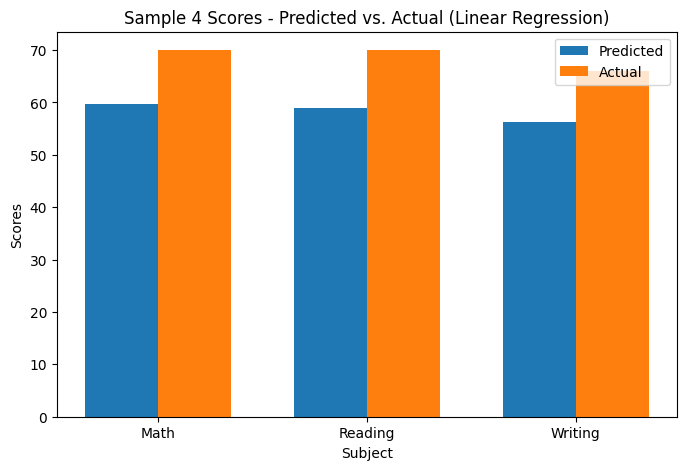

Sample 5:
Predicted Math Score: 80.0279997647855
Actual Math Score: 90
Predicted Reading Score: 72.28354573667895
Actual Reading Score: 80
Predicted Writing Score: 66.86931793215872
Actual Writing Score: 78
--------------------


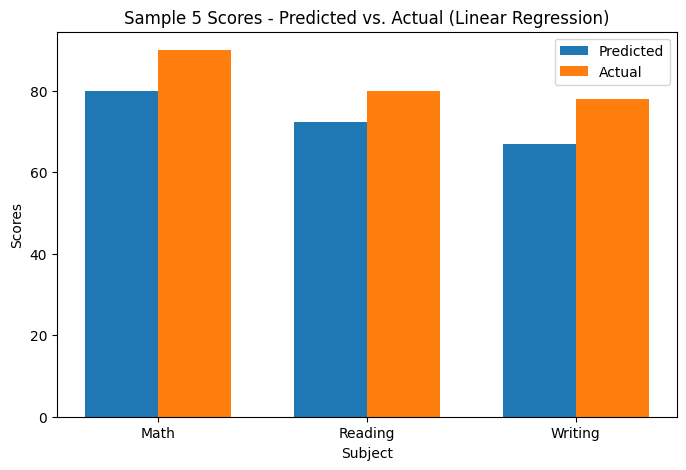

Sample 6:
Predicted Math Score: 58.284010118443284
Actual Math Score: 51
Predicted Reading Score: 57.96006832331567
Actual Reading Score: 54
Predicted Writing Score: 53.52628510829801
Actual Writing Score: 51
--------------------


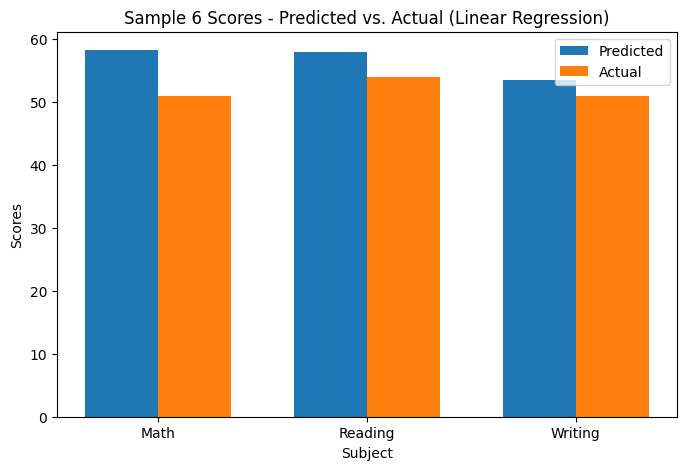



Sample Forecasts using Random Forest:

Sample 1:
Predicted Math Score: 84.16047619047619
Actual Math Score: 67
Predicted Reading Score: 82.64857142857143
Actual Reading Score: 71
Predicted Writing Score: 82.96969841269842
Actual Writing Score: 70
--------------------


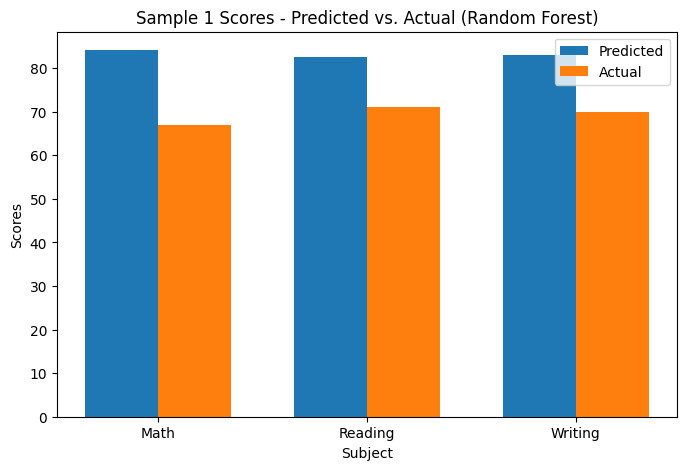

Sample 2:
Predicted Math Score: 70.34384595959597
Actual Math Score: 78
Predicted Reading Score: 71.22434812409814
Actual Reading Score: 76
Predicted Writing Score: 68.78753066378069
Actual Writing Score: 80
--------------------


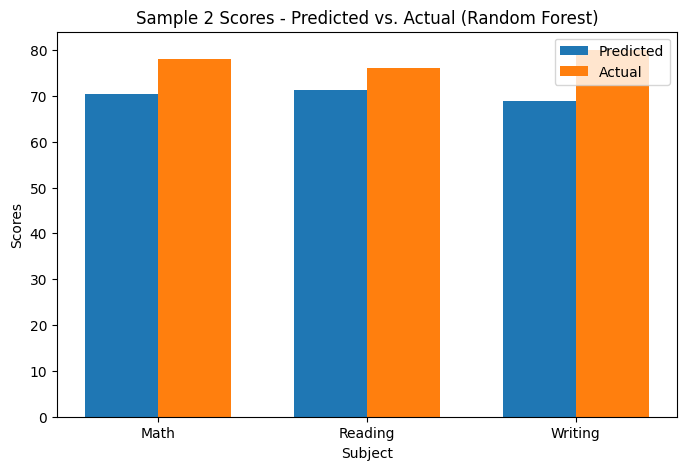

Sample 3:
Predicted Math Score: 69.24540476190475
Actual Math Score: 39
Predicted Reading Score: 78.26814285714286
Actual Reading Score: 52
Predicted Writing Score: 84.13414285714285
Actual Writing Score: 58
--------------------


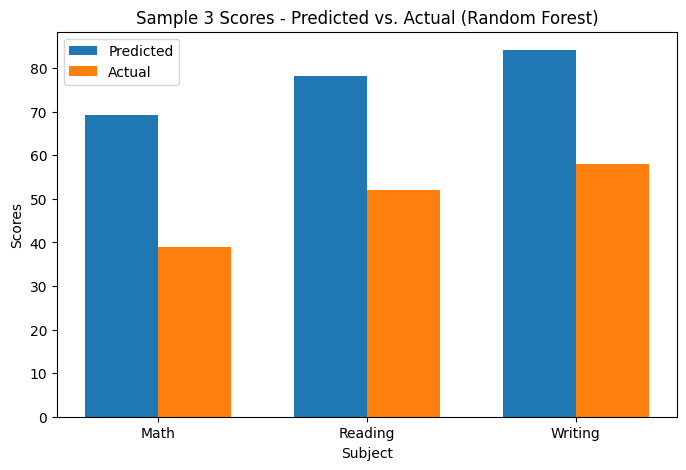

Sample 4:
Predicted Math Score: 65.64879761904761
Actual Math Score: 70
Predicted Reading Score: 64.82433333333333
Actual Reading Score: 70
Predicted Writing Score: 61.547333333333334
Actual Writing Score: 66
--------------------


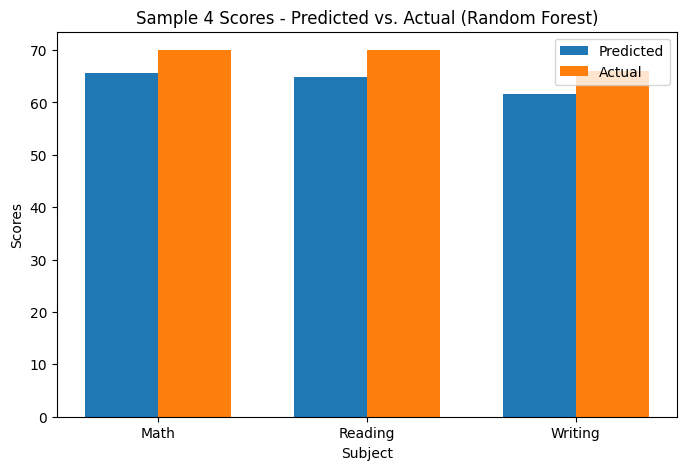

Sample 5:
Predicted Math Score: 92.05398809523813
Actual Math Score: 90
Predicted Reading Score: 84.72921428571428
Actual Reading Score: 80
Predicted Writing Score: 80.32384523809525
Actual Writing Score: 78
--------------------


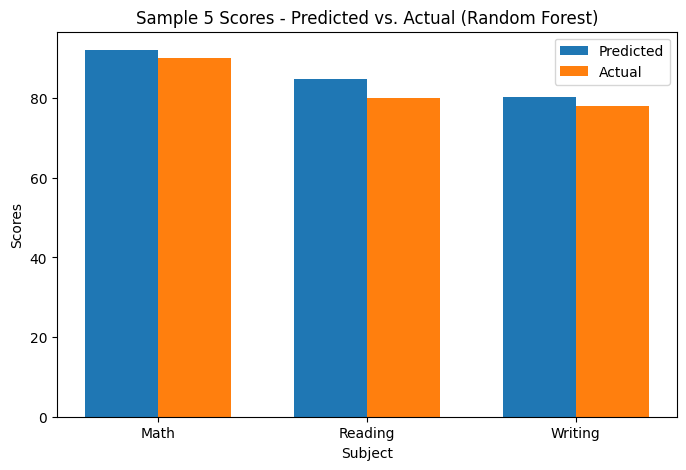

Sample 6:
Predicted Math Score: 61.373677364302345
Actual Math Score: 51
Predicted Reading Score: 62.955335095460086
Actual Reading Score: 54
Predicted Writing Score: 61.266861555111525
Actual Writing Score: 51
--------------------


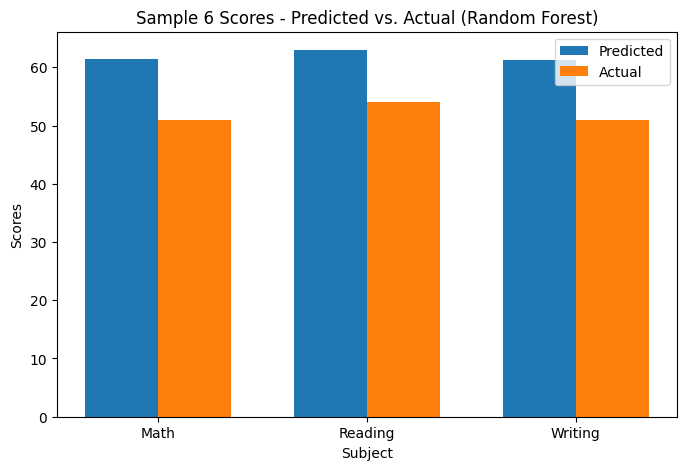



Sample Forecasts using Gradient Boosting:

Sample 1:
Predicted Math Score: 81.11362454806667
Actual Math Score: 67
Predicted Reading Score: 84.70399197023765
Actual Reading Score: 71
Predicted Writing Score: 86.525713764338
Actual Writing Score: 70
--------------------


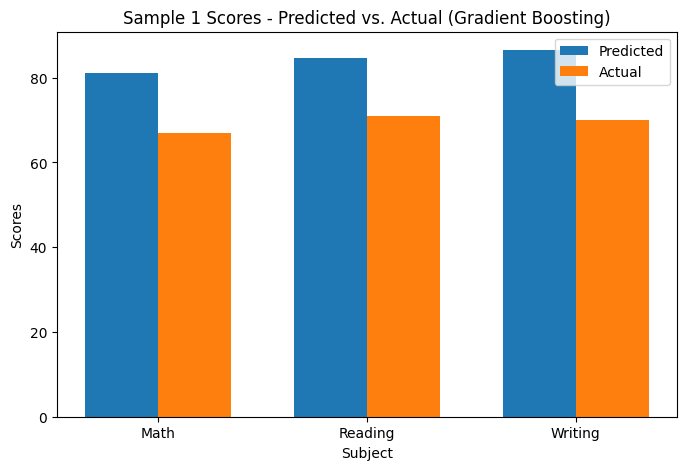

Sample 2:
Predicted Math Score: 78.93037373985632
Actual Math Score: 78
Predicted Reading Score: 74.10690968682636
Actual Reading Score: 76
Predicted Writing Score: 73.91506190704828
Actual Writing Score: 80
--------------------


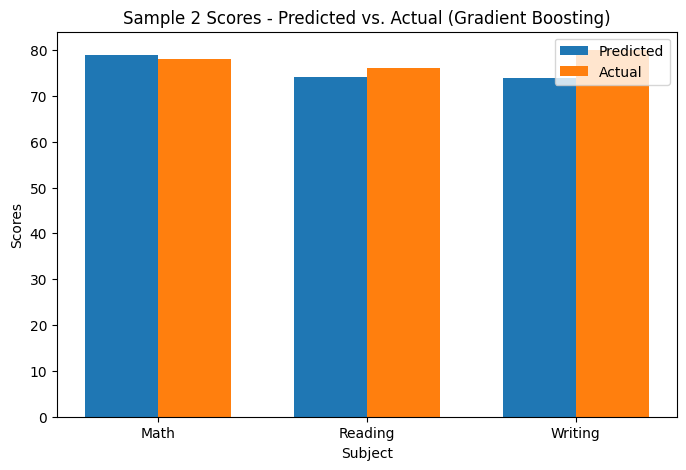

Sample 3:
Predicted Math Score: 58.78830938616087
Actual Math Score: 39
Predicted Reading Score: 72.04262247416312
Actual Reading Score: 52
Predicted Writing Score: 74.31311874431219
Actual Writing Score: 58
--------------------


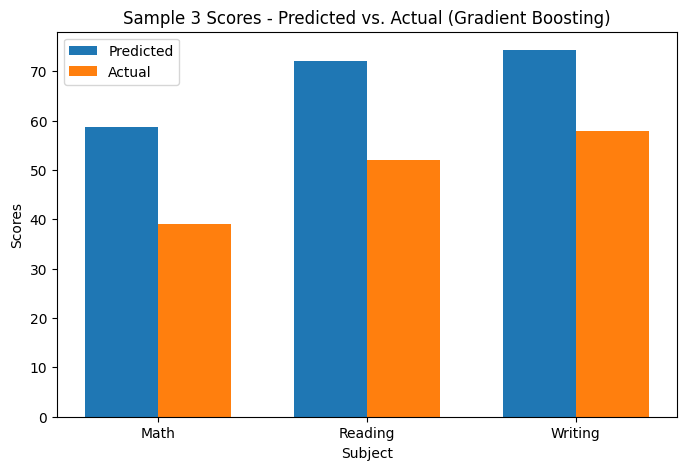

Sample 4:
Predicted Math Score: 63.2443523797881
Actual Math Score: 70
Predicted Reading Score: 60.3960873965725
Actual Reading Score: 70
Predicted Writing Score: 56.66020699201376
Actual Writing Score: 66
--------------------


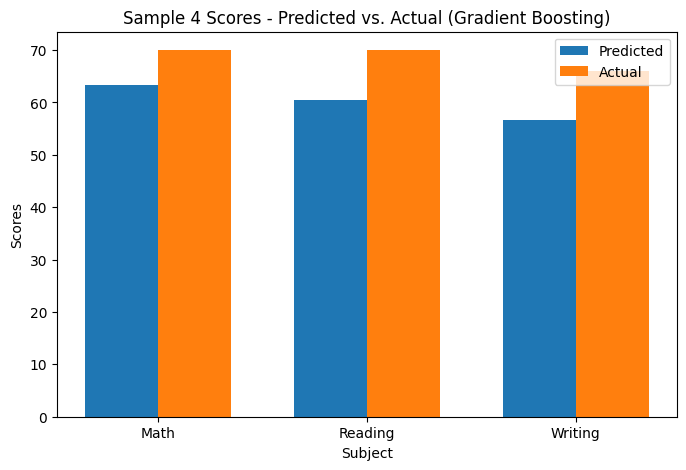

Sample 5:
Predicted Math Score: 83.90467830119776
Actual Math Score: 90
Predicted Reading Score: 74.15035665112791
Actual Reading Score: 80
Predicted Writing Score: 69.67492748274745
Actual Writing Score: 78
--------------------


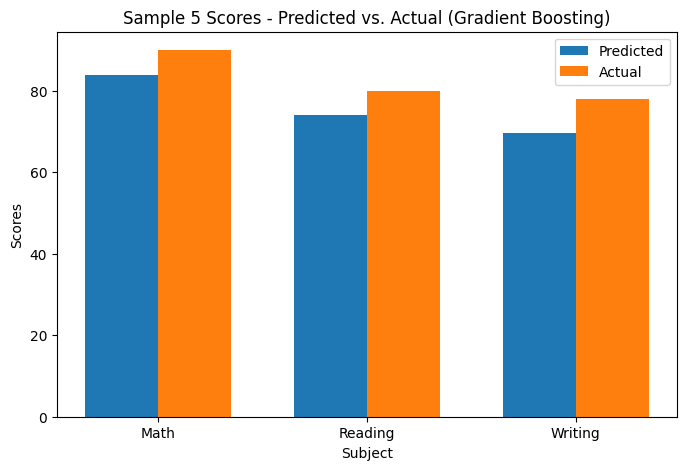

Sample 6:
Predicted Math Score: 59.792357491987175
Actual Math Score: 51
Predicted Reading Score: 59.48534785906171
Actual Reading Score: 54
Predicted Writing Score: 56.49619073301898
Actual Writing Score: 51
--------------------


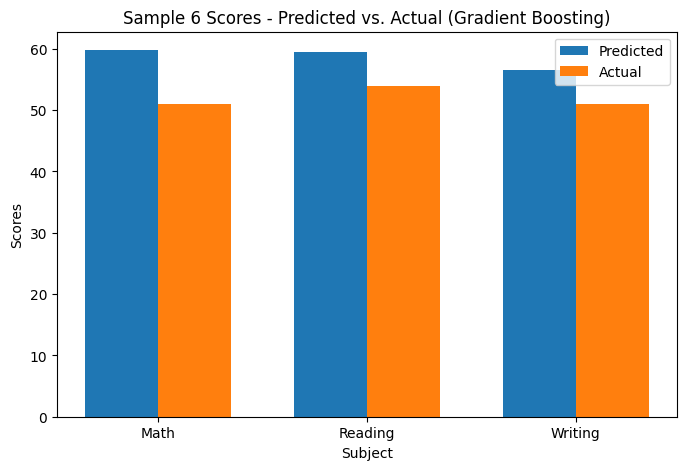



Sample Forecasts using XGBoost:

Sample 1:
Predicted Math Score: 90.79913
Actual Math Score: 67
Predicted Reading Score: 93.00789
Actual Reading Score: 71
Predicted Writing Score: 95.01237
Actual Writing Score: 70
--------------------


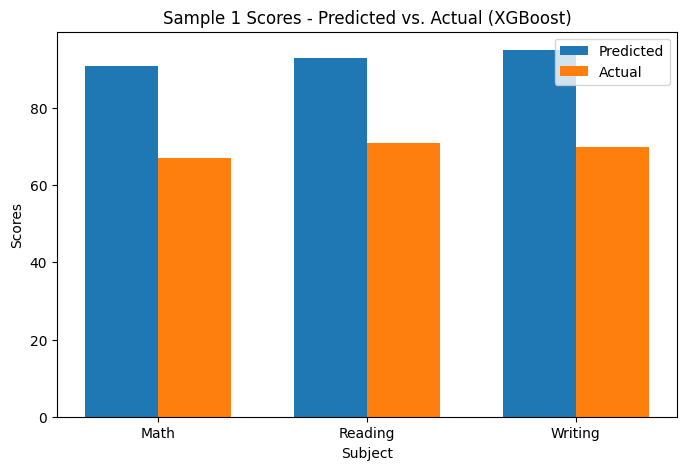

Sample 2:
Predicted Math Score: 69.75926
Actual Math Score: 78
Predicted Reading Score: 70.65969
Actual Reading Score: 76
Predicted Writing Score: 68.209175
Actual Writing Score: 80
--------------------


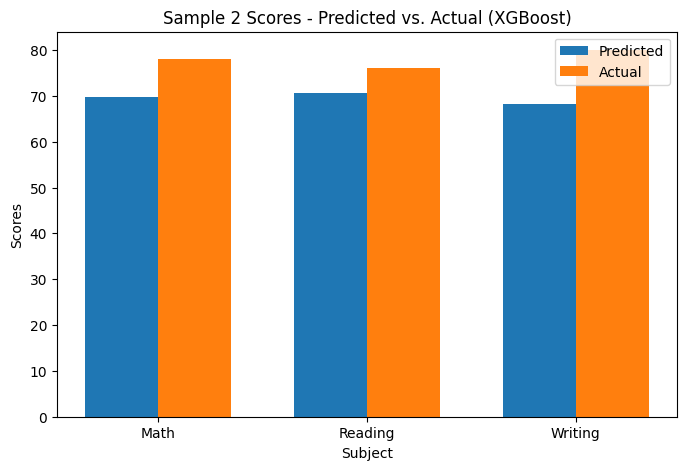

Sample 3:
Predicted Math Score: 72.40009
Actual Math Score: 39
Predicted Reading Score: 80.22496
Actual Reading Score: 52
Predicted Writing Score: 85.61548
Actual Writing Score: 58
--------------------


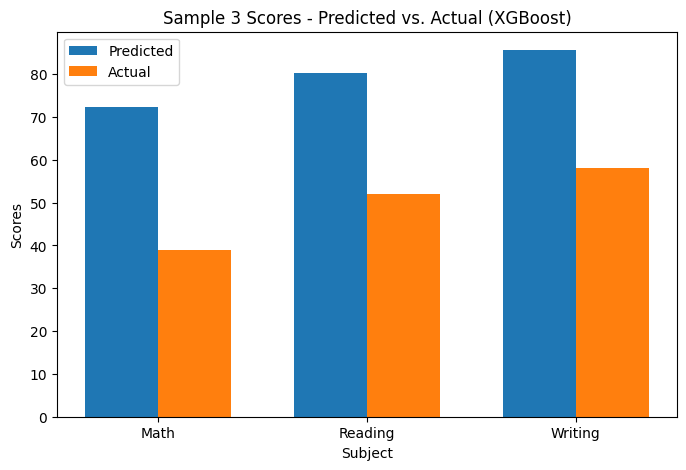

Sample 4:
Predicted Math Score: 66.30775
Actual Math Score: 70
Predicted Reading Score: 63.996033
Actual Reading Score: 70
Predicted Writing Score: 59.910698
Actual Writing Score: 66
--------------------


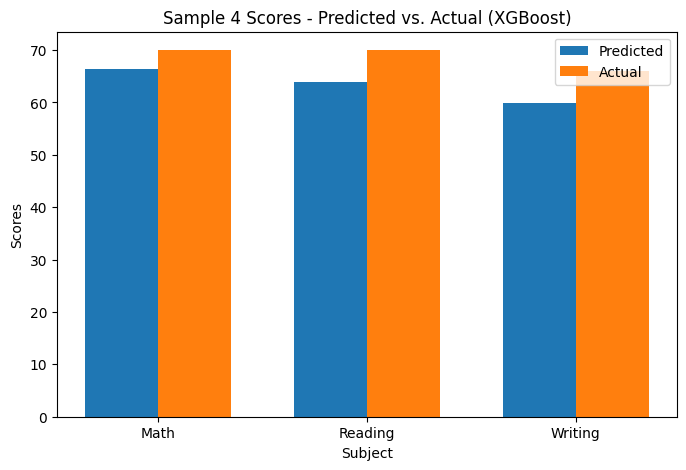

Sample 5:
Predicted Math Score: 92.41552
Actual Math Score: 90
Predicted Reading Score: 85.21097
Actual Reading Score: 80
Predicted Writing Score: 80.96074
Actual Writing Score: 78
--------------------


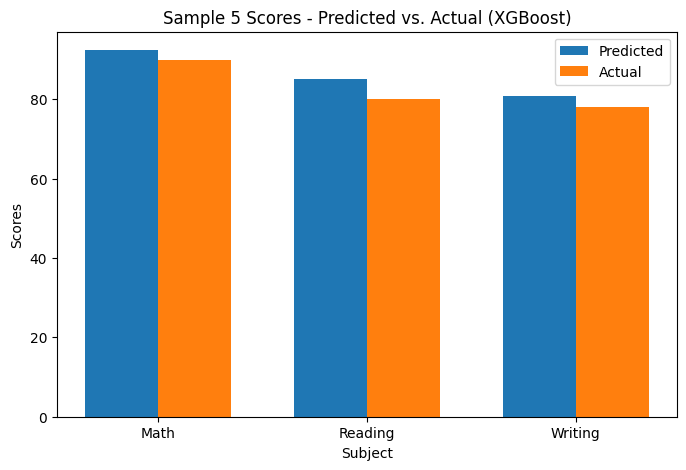

Sample 6:
Predicted Math Score: 60.912296
Actual Math Score: 51
Predicted Reading Score: 62.822647
Actual Reading Score: 54
Predicted Writing Score: 61.071526
Actual Writing Score: 51
--------------------


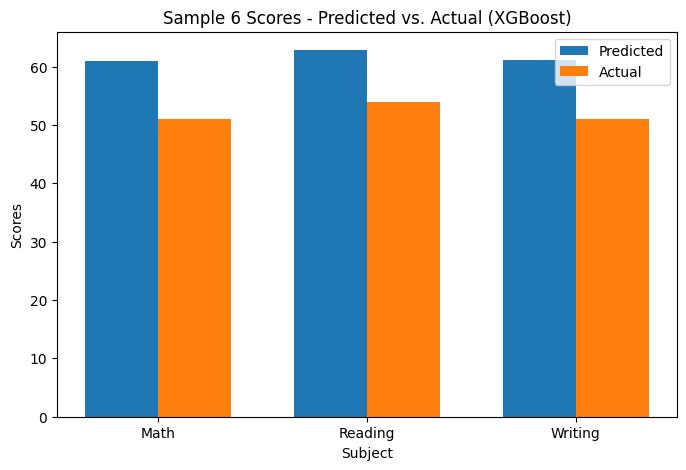

In [9]:
import numpy as np
import matplotlib.pyplot as plt

# Choose a few samples from the test set
sample_indices = [0, 1, 2, 3, 4, 5]
X_sample = X_test.iloc[sample_indices]

# Define models
models = [
    ('Linear Regression', LinearRegression()),
    ('Random Forest', RandomForestRegressor(random_state=42)),
    ('Gradient Boosting', GradientBoostingRegressor(random_state=42)),
    ('XGBoost', XGBRegressor(random_state=42))
]

# Perform some forecasts using the trained models
for name, model in models:
    print(f"Sample Forecasts using {name}:\n")
    pipeline = Pipeline(steps=[('preprocessor', preprocessor), ('model', model)])
    pipeline.fit(X_train, y_math_train)
    math_pred = pipeline.predict(X_sample)
    pipeline.fit(X_train, y_reading_train)
    reading_pred = pipeline.predict(X_sample)
    pipeline.fit(X_train, y_writing_train)
    writing_pred = pipeline.predict(X_sample)
    
    # Print the predicted scores along with the actual scores for comparison
    for i, index in enumerate(sample_indices):
        print(f"Sample {i+1}:")
        print("Predicted Math Score:", math_pred[i])
        print("Actual Math Score:", y_math_test.iloc[index])
        print("Predicted Reading Score:", reading_pred[i])
        print("Actual Reading Score:", y_reading_test.iloc[index])
        print("Predicted Writing Score:", writing_pred[i])
        print("Actual Writing Score:", y_writing_test.iloc[index])
        print("--------------------")
        
        # Plot bar graph for the current sample
        plt.figure(figsize=(8, 5))
        subjects = ['Math', 'Reading', 'Writing']
        predicted_scores = [math_pred[i], reading_pred[i], writing_pred[i]]
        actual_scores = [y_math_test.iloc[index], y_reading_test.iloc[index], y_writing_test.iloc[index]]
        
        bar_width = 0.35
        index = np.arange(len(subjects))
        
        plt.bar(index, predicted_scores, bar_width, label='Predicted')
        plt.bar(index + bar_width, actual_scores, bar_width, label='Actual')
        
        plt.xlabel('Subject')
        plt.ylabel('Scores')
        plt.title(f'Sample {i+1} Scores - Predicted vs. Actual ({name})')
        plt.xticks(index + bar_width / 2, subjects)
        plt.legend()
        plt.show()

    print("\n")



Based on the results obtained from the sample forecasts using various predictive models (Linear Regression, Random Forest, Gradient Boosting, and XGBoost), we can conclude that predictive models can indeed be developed to forecast students' academic performance based on demographic characteristics.
